In [28]:
import numpy as np
import altair as alt
import json
import seaborn as sns 
from evaluation.avalanche_criterion import avalanche_criterion
from evaluation.fixed_points import fixed_ponts
from evaluation.uniformity import get_ddt
from evaluation.linearity import evaluate
from sboxes.loader import load as load_sbox
from sboxes import SBox
from sboxes.loader import load as load_sbox
from evaluation.identity_sbox import IdentitySBox

from evaluation.graphics.graphics_with_altair import (
    compare_tv_distance_altair,
    compare_max_probability_altair,
    compare_mixing_times_altair,
    compare_mixing_times_spectrals_altair
)

# Para que Altair muestre los charts en el notebook
alt.renderers.enable('default')

bits = 8
bits_str = str(bits)

In [29]:
from evaluation.fixed_points      import fixed_ponts

number_of_owns = 50
own_sboxes_index = range(1,number_of_owns+1)

selected = []

for i in own_sboxes_index:
    with open(f"data/{bits_str}x{bits_str}_sboxes/sbox_{bits_str}_{i}.json", "r", encoding="utf-8") as f:
        data = json.load(f)
        table = list(map(lambda x: hex(x), data["best"]))
        n_in  = int(np.log2(len(table)))                    # size of the input
        n_out = int(np.ceil(np.log2(max(data["best"])+1)))  # size of the output
        name = f"Variant #{i}"    
        sbox = SBox(n_in, n_out, table, name)                    
        fijos = fixed_ponts(sbox, detail=True)[1]
        if fijos == 0:
            selected.append(i)
print(f"{selected}")

[3, 5, 10, 17, 18, 19, 22, 25, 28, 29, 30, 32, 33, 37, 38, 46, 50]


In [30]:
selected = [17, 22, 29, 33, 38]

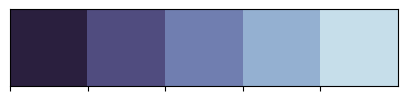

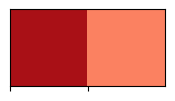

In [31]:
number_of_owns = len(selected)
own_sboxes_index = selected

COLORS_FOR_OWNS = sns.color_palette("ch:s=.25,rot=-.25", n_colors=number_of_owns) [::-1]
#sns.palplot(sns.color_palette("Reds", n_colors=10))[::-3]  # Colores para las S-Boxes propias
COLORS_FOR_CLASICS = sns.color_palette("Reds", n_colors=6)[::-3]
sns.palplot(COLORS_FOR_OWNS)
sns.palplot(COLORS_FOR_CLASICS)

In [32]:
to_proof = ["aes", "07_Romulus"]
specs_clasics = []

for sbox_link in to_proof:
    sbox = load_sbox(f"data/clasics/{sbox_link}.json")
    specs_clasics.append({
        'name': sbox.name,
        'table': sbox.table.tolist(),
        'n_in': sbox.input_size,
        'n_out': sbox.output_size,
        'color': COLORS_FOR_CLASICS[len(specs_clasics) % len(COLORS_FOR_CLASICS)],
        'sbox': sbox
        
    })
    print(f"Procesando S-Box: {sbox.name} ({sbox.input_size}x{sbox.output_size})")

Procesando S-Box: AES (8x8)
Procesando S-Box: Romulus/Skinny-128-384+ (8x8)


In [33]:
specs_owns = []

for i in own_sboxes_index:

    with open(f"data/{bits_str}x{bits_str}_sboxes/sbox_{bits_str}_{i}.json", "r", encoding="utf-8") as f:
        data = json.load(f)
    
        table = list(map(lambda x: hex(x), data["best"]))
        n_in  = int(np.log2(len(table)))                    # size of the input
        n_out = int(np.ceil(np.log2(max(data["best"])+1)))  # size of the output
        name = f"Variant #{i}"
            
        sbox = SBox(n_in, n_out, table, name)                    
        specs_owns.append({
            "name": name,              
            "table": data["best"],
            "n_in": n_in,
            "n_out": n_out,
            "color": COLORS_FOR_OWNS[len(specs_owns) % len(COLORS_FOR_OWNS)],
            "sbox":  sbox
        })

print(f"{len(specs_owns)} S-Boxes cargadas desde data.json")


5 S-Boxes cargadas desde data.json


In [34]:

specs = specs_clasics + specs_owns

import matplotlib.colors as mcolors
for spec in specs:
    spec['color'] = mcolors.to_hex(spec['color'])

In [35]:
chart_tv = compare_tv_distance_altair(
    specs,
    r_values=list(range(1,11)),
    log_scale=True,
    detail=True
)
chart_tv

|   r |         AES |   Romulus/Skinny-128-384+ |   Variant #17 |   Variant #22 |   Variant #29 |   Variant #33 |   Variant #38 |
|----:|------------:|--------------------------:|--------------:|--------------:|--------------:|--------------:|--------------:|
|   1 | 0.501961    |                0.976471   |   0.623529    |   0.627451    |   0.627451    |   0.623529    |   0.623529    |
|   2 | 0.0270309   |                0.854933   |   0.0495227   |   0.0517504   |   0.0491563   |   0.0506671   |   0.0495531   |
|   3 | 0.00169876  |                0.523007   |   0.0042316   |   0.00423548  |   0.00447652  |   0.00421289  |   0.0043653   |
|   4 | 0.000109373 |                0.316561   |   0.000363535 |   0.000355537 |   0.000366516 |   0.000363332 |   0.000369989 |
|   5 | 6.94875e-06 |                0.155007   |   3.20555e-05 |   2.9709e-05  |   3.06079e-05 |   3.04515e-05 |   3.07912e-05 |
|   6 | 4.44987e-07 |                0.0825113  |   2.57428e-06 |   2.45531e-06 |   2.5473

alt.Chart(...)

In [36]:
chart_mp = compare_max_probability_altair(
    specs,
    r_values=list(range(1,11)),
    log_scale=False,
    detail=True
)
chart_mp

|   r |        AES |   Romulus/Skinny-128-384+ |   Variant #17 |   Variant #22 |   Variant #29 |   Variant #33 |   Variant #38 |
|----:|-----------:|--------------------------:|--------------:|--------------:|--------------:|--------------:|--------------:|
|   1 | 0.015625   |                0.25       |    0.0234375  |    0.0234375  |    0.0234375  |    0.0234375  |    0.0234375  |
|   2 | 0.00506592 |                0.1875     |    0.00561523 |    0.0057373  |    0.00567627 |    0.00579834 |    0.0057373  |
|   3 | 0.00398874 |                0.0942383  |    0.0040822  |    0.00407743 |    0.00408268 |    0.00407648 |    0.00406456 |
|   4 | 0.00392645 |                0.0523682  |    0.00393606 |    0.00393476 |    0.00393432 |    0.00393433 |    0.00393455 |
|   5 | 0.00392187 |                0.021579   |    0.00392263 |    0.00392257 |    0.00392259 |    0.00392253 |    0.00392259 |
|   6 | 0.00392159 |                0.0116473  |    0.00392166 |    0.00392165 |    0.00392166 | 

alt.Chart(...)

In [37]:
chart_mix = compare_mixing_times_altair(
    specs,
    epsilons=[10**(-i) for i in range(6,7)],
    max_steps=10000,
    log_scale=True,
)
chart_mix

[1e-06]
AES with ε=1e-06: 6
Romulus/Skinny-128-384+ with ε=1e-06: 24
Variant #17 with ε=1e-06: 7
Variant #22 with ε=1e-06: 7
Variant #29 with ε=1e-06: 7
Variant #33 with ε=1e-06: 7
Variant #38 with ε=1e-06: 7


alt.Chart(...)

In [38]:
chart_spec = compare_mixing_times_spectrals_altair(
    specs,
    epsilons=[10**(-i) for i in range(1,10)],
    max_steps=10000,
    log_scale=True,
)
chart_spec

alt.Chart(...)

# Clasicas


=== Métricas de S-Boxes ===
                   name  uniformity  max_ddt  fixed_points  non_linearity  avg_sac  max_std_sac
                    AES           4      256             0          112.0 0.504883     0.036644
Romulus/Skinny-128-384+          64      256             1           64.0 0.316406     0.340897
            Variant #17           6      256             0          100.0 0.498291     0.039788
            Variant #22           6      256             0          100.0 0.508789     0.065364
            Variant #29           6      256             0          100.0 0.502686     0.051081
            Variant #33           6      256             0          100.0 0.505371     0.042612
            Variant #38           6      256             0          100.0 0.493164     0.057906


c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


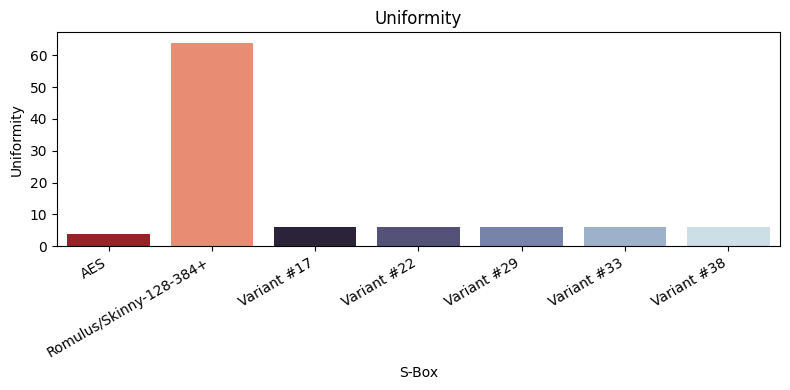

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


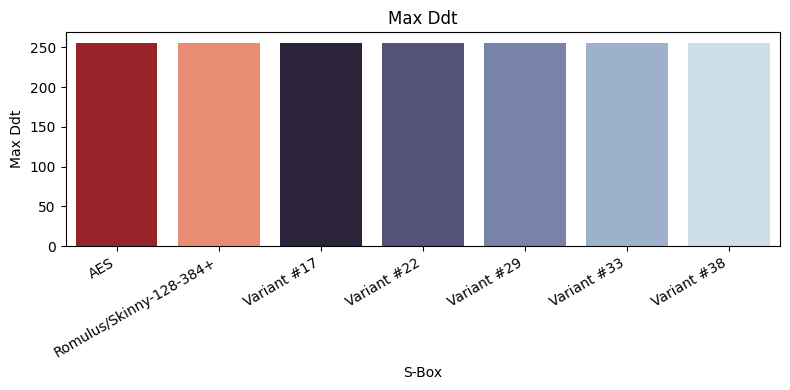

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


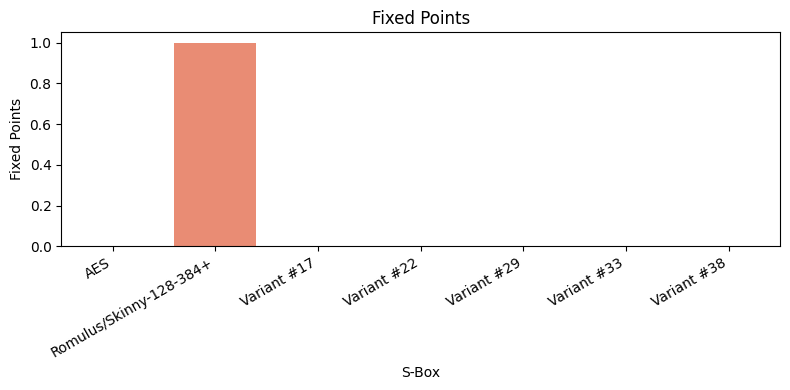

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


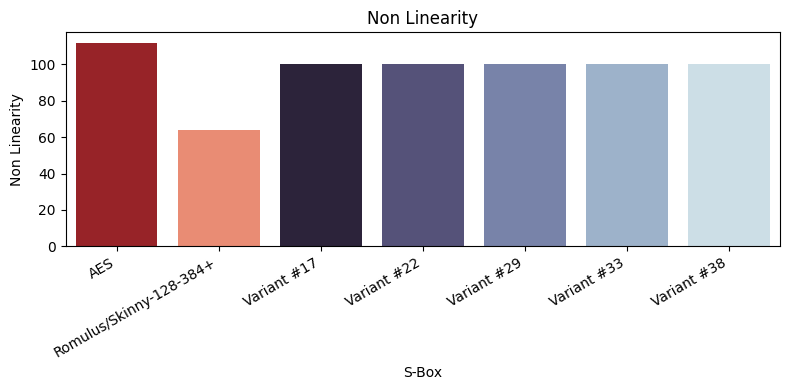

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


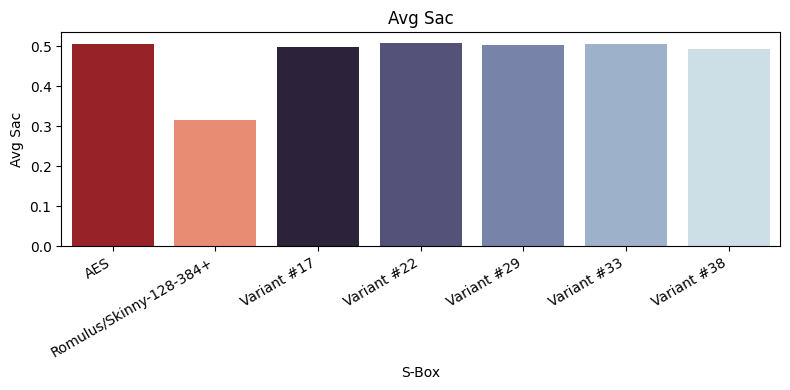

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


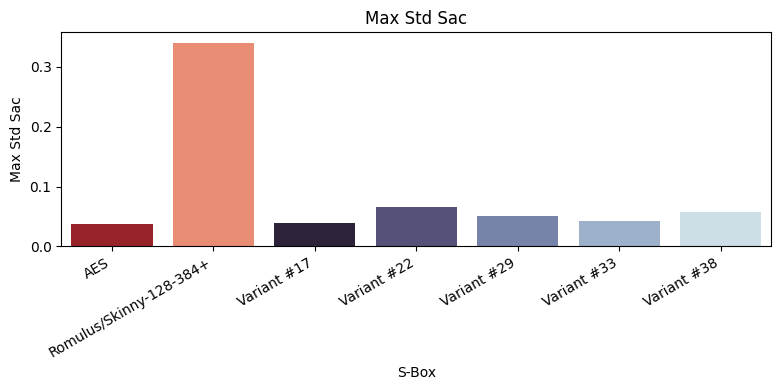

,name,uniformity,max_ddt,fixed_points,non_linearity,avg_sac,max_std_sac
0,AES,4,256,0,112.0,0.504883,0.036644
1,Romulus/Skinny-128-384+,64,256,1,64.0,0.316406,0.340897
2,Variant #17,6,256,0,100.0,0.498291,0.039788
3,Variant #22,6,256,0,100.0,0.508789,0.065364
4,Variant #29,6,256,0,100.0,0.502686,0.051081
5,Variant #33,6,256,0,100.0,0.505371,0.042612
6,Variant #38,6,256,0,100.0,0.493164,0.057906


In [39]:
from evaluation.sbox_metrics_analysis import run_all_metrics

run_all_metrics(specs)

# Ranking

In [40]:
import pandas as pd

# Carga el resumen de métricas generado por run_all_metrics
df = pd.read_csv('sbox_metrics_summary.csv')

# Calcula desviación de avg_sac respecto a 0.5 (ideal SAC = 0.5)
df['sac_error'] = (df['avg_sac'] - 0.5).abs()

# Genera rankings individuales (menor es mejor salvo non_linearity)
df['r_uniformity']    = df['uniformity'].rank(ascending=True)
df['r_max_ddt']       = df['max_ddt'].rank(ascending=True)
df['r_fixed_points']  = df['fixed_points'].rank(ascending=True)
df['r_non_linearity'] = df['non_linearity'].rank(ascending=False)
df['r_sac_error']     = df['sac_error'].rank(ascending=True)
df['r_max_std_sac']   = df['max_std_sac'].rank(ascending=True)

# Suma de rangos como puntaje agregado
rank_cols = ['r_uniformity','r_max_ddt','r_fixed_points',
             'r_non_linearity','r_sac_error','r_max_std_sac']
df['total_rank'] = df[rank_cols].sum(axis=1)

# Ordena y muestra top 5
top5 = df.sort_values('total_rank').reset_index(drop=True)
to_display = top5[['name','total_rank','non_linearity','uniformity',
                   'fixed_points','avg_sac','max_ddt','max_std_sac']].head(5)

print(to_display.to_markdown(index=False))
#import ace_tools as tools; tools.display_dataframe_to_user(name="Top 5 S-Boxes por puntaje agregado", dataframe=to_display)


| name        |   total_rank |   non_linearity |   uniformity |   fixed_points |   avg_sac |   max_ddt |   max_std_sac |
|:------------|-------------:|----------------:|-------------:|---------------:|----------:|----------:|--------------:|
| AES         |         13.5 |             112 |            4 |              0 |  0.504883 |       256 |     0.0366439 |
| Variant #17 |         18.5 |             100 |            6 |              0 |  0.498291 |       256 |     0.0397882 |
| Variant #29 |         21.5 |             100 |            6 |              0 |  0.502686 |       256 |     0.0510808 |
| Variant #33 |         22.5 |             100 |            6 |              0 |  0.505371 |       256 |     0.0426122 |
| Variant #38 |         25.5 |             100 |            6 |              0 |  0.493164 |       256 |     0.0579061 |
